<div style="background: linear-gradient(135deg, #123c69, #2a9d8f); color: white; padding: 28px; border-radius: 12px; text-align: center; font-family: Arial, sans-serif; box-shadow: 0 4px 12px rgba(0, 0, 0, 0.18); box-sizing: border-box; width: 100%; margin: 0;">
    <h1 style="margin: 0; font-size: 30px; color: white;">
        Heart Disease Prediction using Machine Learning
    </h1>
</div>

<h2 style="color:#1f4e79;">1. Business problem</h2>

<p style="text-align:justify;">
Cardiovascular diseases are among the leading causes of death worldwide. Hospitals and healthcare professionals need to quickly identify patients at high risk of developing heart disease so that appropriate preventive measures can be put in place. However, assessing this risk manually can be complex because of the large number of medical factors involved.
</p>

<p style="text-align:justify;">
The organization therefore wants to use patients' medical data to improve the early identification of people at risk.
</p>

<h2 style="color:#1f4e79;">2. Project objectives</h2>

<p style="text-align:justify;">
The main objective of the project is to develop a dataset ready for Machine Learning in order to predict the presence or absence of heart disease in a patient.
</p>

| Variable | Description | Values |
|---|---|---|
| **Age** | Patient age | [years] |
| **Sex** | Patient sex | M: Male, F: Female |
| **ChestPainType** | Type of chest pain | TA: Typical angina, ATA: Atypical angina, NAP: Non-anginal pain, ASY: Asymptomatic |
| **RestingBP** | Resting blood pressure | [mm Hg] |
| **Cholesterol** | Serum cholesterol | [mg/dl] |
| **FastingBS** | Fasting blood sugar | 1: if FastingBS > 120 mg/dl, 0: otherwise |
| **RestingECG** | Resting electrocardiogram results | Normal: normal, ST: ST-T wave abnormality (T-wave inversions and/or ST-segment elevation or depression > 0.05 mV), LVH: probable or definite left ventricular hypertrophy according to Estes' criteria |
| **MaxHR** | Maximum heart rate achieved | Numeric value between 60 and 202 |
| **ExerciseAngina** | Exercise-induced angina | Y: Yes, N: No |
| **Oldpeak** | Oldpeak = ST | Numeric value measured in depression |
| **ST_Slope** | Slope of the peak exercise ST segment | Up: upsloping, Flat: flat, Down: downsloping |
| **HeartDisease** | Output class | 1: heart disease, 0: normal |

In [1]:
# Import libraries
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Data Inspection

In [2]:
# Load dataset
df = pd.read_csv('heart.csv')
df.head(5)

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
# Dataset dimensions (rows, columns)
print("Rows :", df.shape[0])
print("Columns :", df.shape[1])

Rows : 918
Columns : 12


In [4]:
# Column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [5]:
# Missing values per column
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [6]:
# Duplicates
print("Number of duplicates :", df.duplicated().sum())

Number of duplicates : 0


## Feature engineering and data preprocessing

### Data cleaning

In [7]:
# Handle missing values.
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

### Feature engineering

In [8]:
# 
# ============================================================
# Convert binary variables (0/1) to readable strings
# ============================================================


# --- FastingBS (fasting blood sugar > 120 mg/dl) ---
# Same logic: 0 → 'No' (blood sugar ≤ 120 mg/dl)
#                1 → 'Yes' (blood sugar > 120 mg/dl)
df['FastingBS'] = df['FastingBS'].astype(str).replace({'0': 'No', '1': 'Yes'})

### Outliers detection

In [9]:
# ============================================================
# 1. DETECTION (thresholds computed on the ORIGINAL df)
# ============================================================
numeric_cols = df.select_dtypes(include='number').columns
outlier_summary = []
outlier_mask = pd.Series(False, index=df.index)
seuils_iqr = {}   # ← store the bounds BEFORE removal

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    seuils_iqr[col] = (lower_bound, upper_bound)   # ← save

    mask = (df[col] < lower_bound) | (df[col] > upper_bound)
    outlier_mask |= mask

    outlier_summary.append({
        'Variable': col,
        'Lower threshold': lower_bound,
        'Upper threshold': upper_bound,
        'Number of outliers': mask.sum()
    })

outlier_summary = pd.DataFrame(outlier_summary)
display(outlier_summary)

# Rows containing at least one outlier
df_outliers = df.loc[outlier_mask]
display(df_outliers)


,Variable,Lower threshold,Upper threshold,Number of outliers
0,Age,27.500,79.500,0
1,RestingBP,90.000,170.000,28
2,Cholesterol,32.625,407.625,183
3,MaxHR,66.000,210.000,2
4,Oldpeak,-2.250,3.750,16
5,HeartDisease,-1.500,2.500,0


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
28,53,F,ATA,113,468,No,Normal,127,N,0.0,Up,0
30,53,M,NAP,145,518,No,Normal,130,N,0.0,Flat,1
68,52,M,ASY,160,246,No,ST,82,Y,4.0,Flat,1
69,44,M,ASY,150,412,No,Normal,170,N,0.0,Up,0
76,32,M,ASY,118,529,No,Normal,130,N,0.0,Flat,1
...,...,...,...,...,...,...,...,...,...,...,...,...
850,62,F,ASY,160,164,No,LVH,145,N,6.2,Down,1
855,68,M,NAP,180,274,Yes,LVH,150,Y,1.6,Flat,1
880,52,M,NAP,172,199,Yes,Normal,162,N,0.5,Up,0
900,58,M,ASY,114,318,No,ST,140,N,4.4,Down,1


In [10]:
# 2. REMOVAL
# ============================================================
n_avant = len(df)
df = df.loc[~outlier_mask].reset_index(drop=True)
n_apres = len(df)

print("=" * 55)
print(f"Before: {n_avant} rows | After: {n_apres} rows "
      f"| Removed: {n_avant - n_apres}")
print("=" * 55)

Before: 918 rows | After: 702 rows | Removed: 216


In [11]:
# 3. CHECK with the ORIGINAL thresholds
# ============================================================
print("\n=== CHECK (original thresholds) ===")
for col, (lb, ub) in seuils_iqr.items():
    reste = ((df[col] < lb) | (df[col] > ub)).sum()
    statut = "✅" if reste == 0 else "⚠️"
    print(f"{statut} {col:15s} → remaining outliers : {reste}")


=== CHECK (original thresholds) ===
✅ Age             → remaining outliers : 0
✅ RestingBP       → remaining outliers : 0
✅ Cholesterol     → remaining outliers : 0
✅ MaxHR           → remaining outliers : 0
✅ Oldpeak         → remaining outliers : 0
✅ HeartDisease    → remaining outliers : 0


In [12]:
# statistical analysis
df.describe(include='all')

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
count,702.000000,702,702,702.000000,702.000000,702,702,702.000000,702,702.000000,702,702.000000
unique,NaN,2,4,NaN,NaN,2,3,NaN,2,NaN,3,NaN
top,NaN,M,ASY,NaN,NaN,No,Normal,NaN,N,NaN,Up,NaN
freq,NaN,534,340,NaN,NaN,588,422,NaN,439,NaN,338,NaN
mean,52.722222,NaN,NaN,131.556980,239.709402,NaN,NaN,140.549858,NaN,0.830912,NaN,0.462963
std,9.535341,NaN,NaN,15.420368,50.684118,NaN,NaN,24.360985,NaN,0.959731,NaN,0.498982
min,28.000000,NaN,NaN,92.000000,85.000000,NaN,NaN,71.000000,NaN,-0.100000,NaN,0.000000
25%,46.000000,NaN,NaN,120.000000,206.000000,NaN,NaN,122.000000,NaN,0.000000,NaN,0.000000
50%,54.000000,NaN,NaN,130.000000,235.000000,NaN,NaN,140.000000,NaN,0.400000,NaN,0.000000
75%,59.000000,NaN,NaN,140.000000,272.000000,NaN,NaN,160.000000,NaN,1.500000,NaN,1.000000


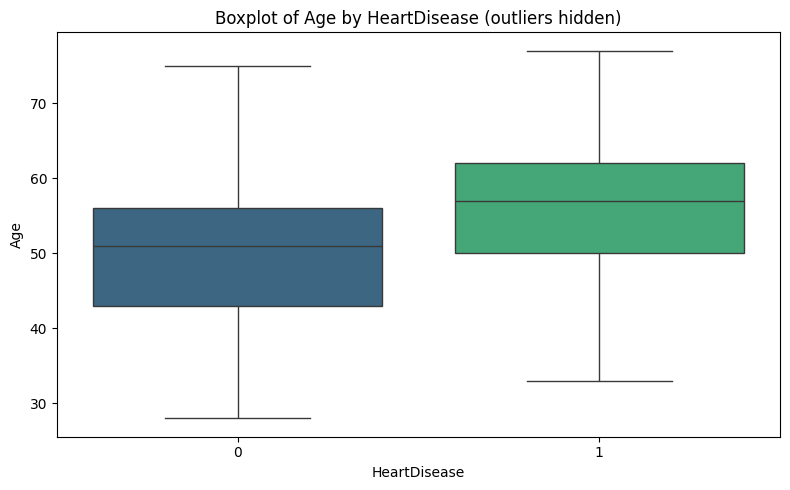

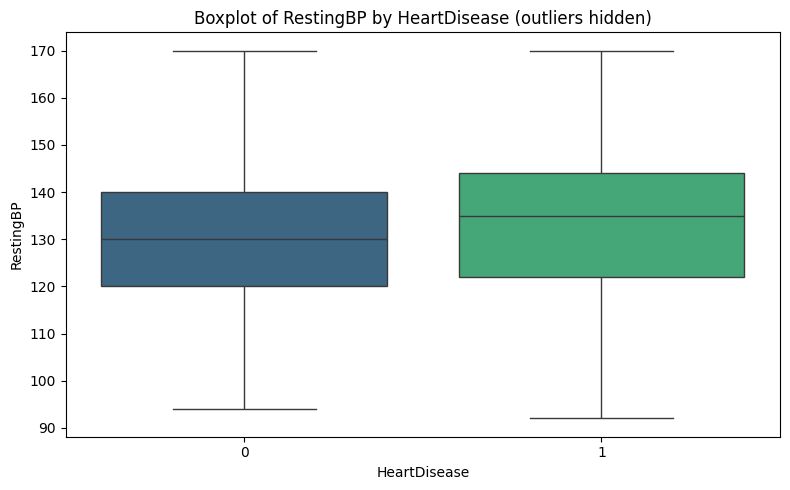

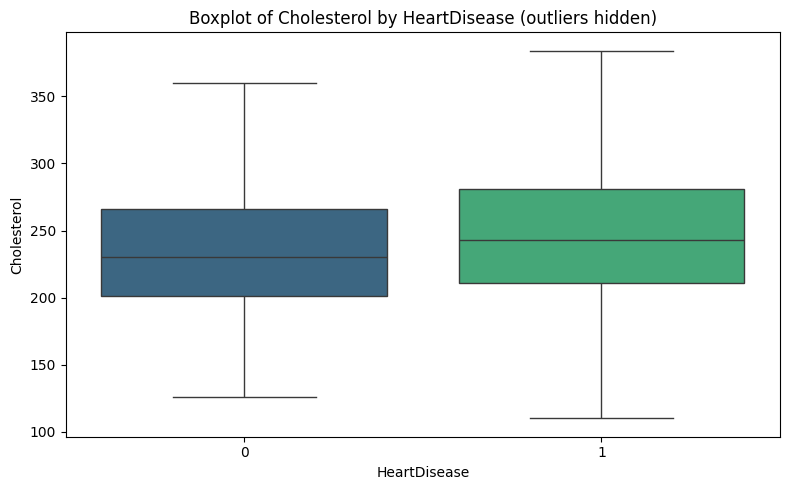

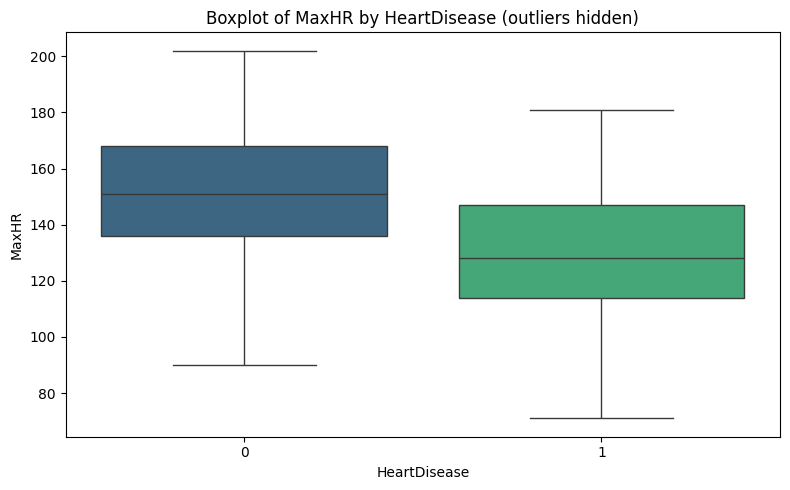

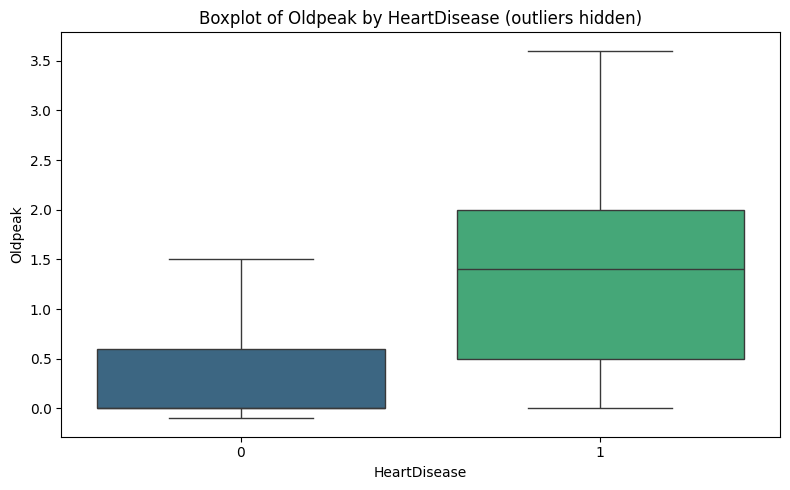

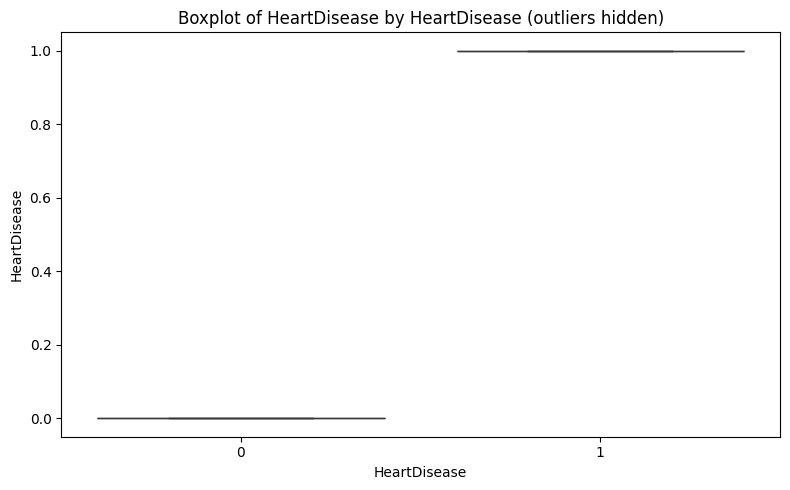

In [13]:
for num_col in df.select_dtypes(include='number').columns:
    plt.figure(figsize=(8, 5))
    sns.boxplot(
        data=df,
        x='HeartDisease',
        y=num_col,
        hue='HeartDisease',
        palette='viridis',
        dodge=False,
        legend=False,
        showfliers=False    # ← hides outlier points in the plot
    )
    plt.title(f'Boxplot of {num_col} by HeartDisease (outliers hidden)')
    plt.tight_layout()
    plt.show()

In [14]:
# List all column names
features = df.columns.tolist()
features

['Age',
 'Sex',
 'ChestPainType',
 'RestingBP',
 'Cholesterol',
 'FastingBS',
 'RestingECG',
 'MaxHR',
 'ExerciseAngina',
 'Oldpeak',
 'ST_Slope',
 'HeartDisease']

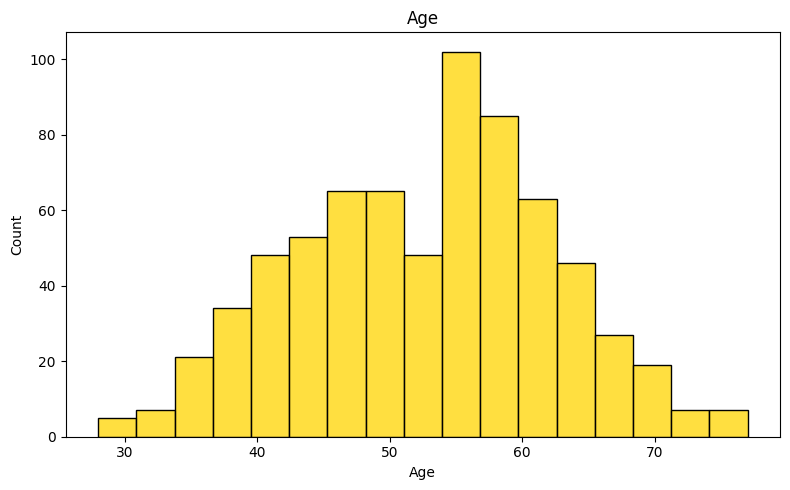

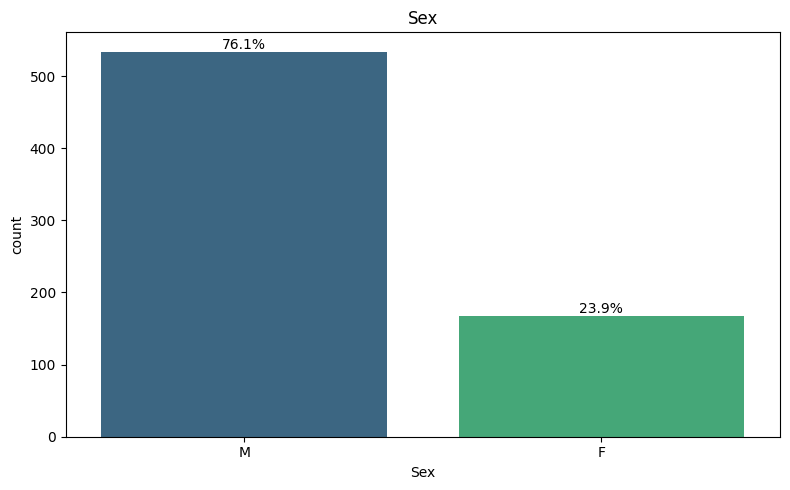

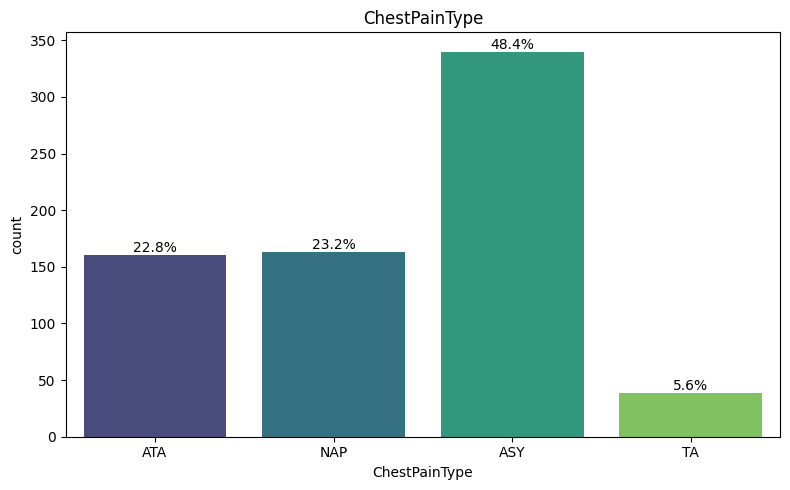

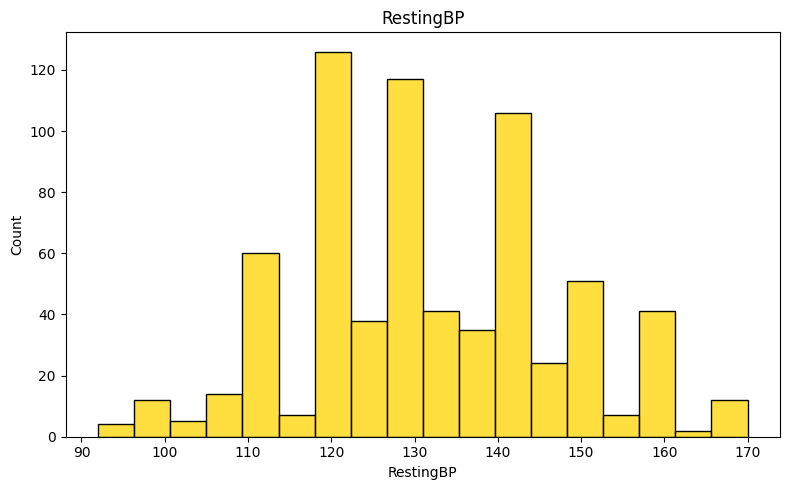

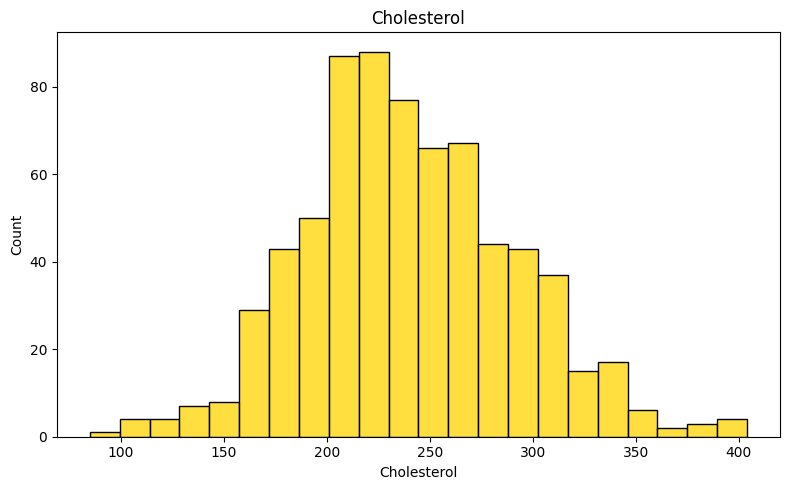

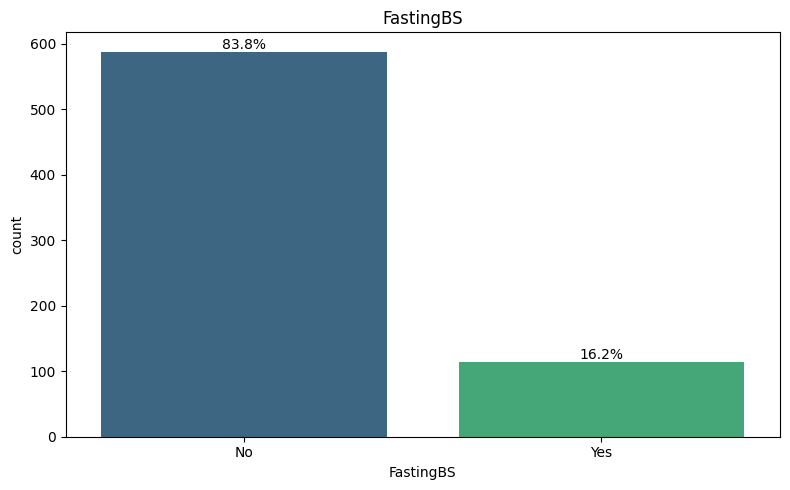

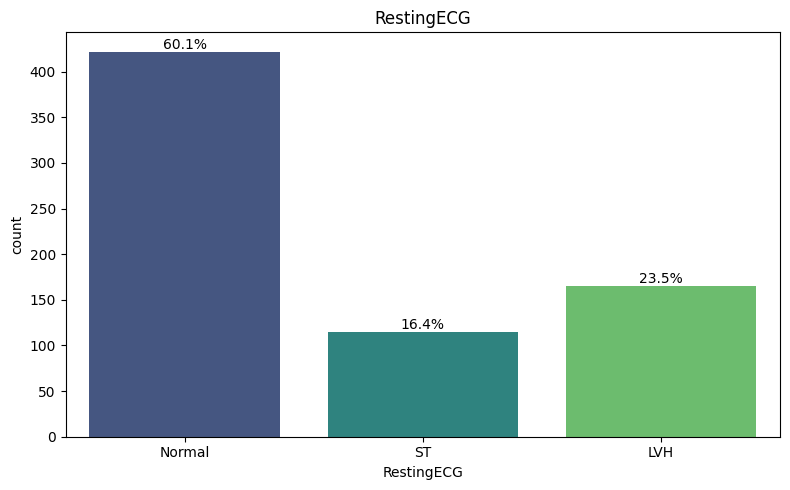

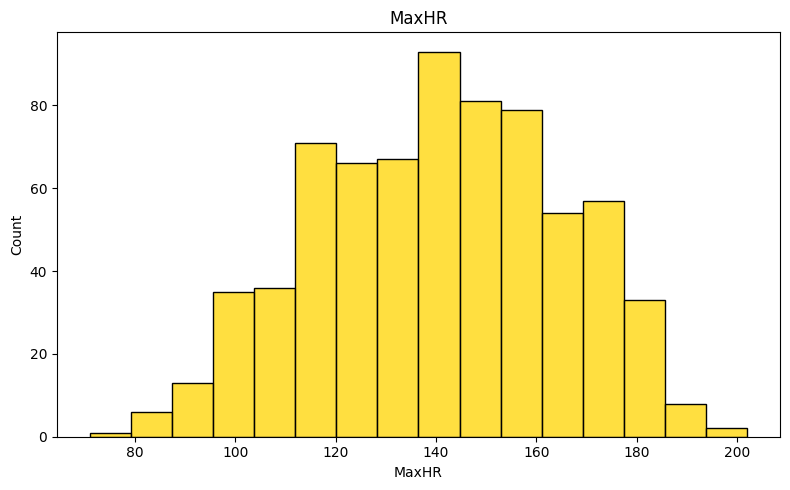

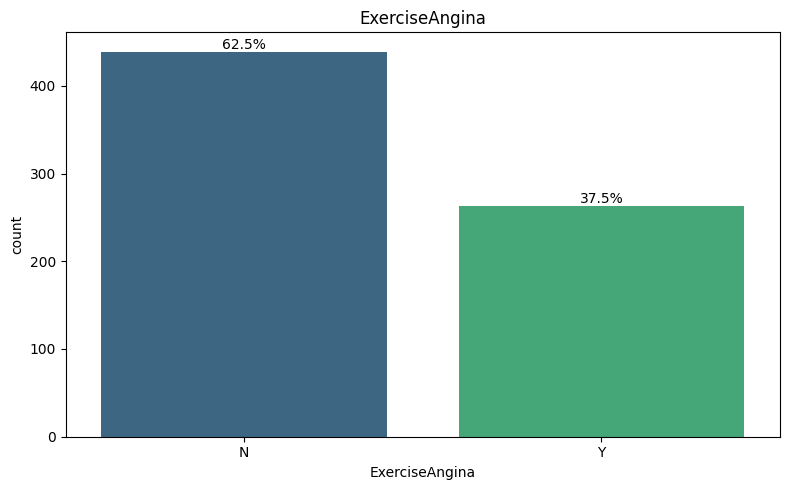

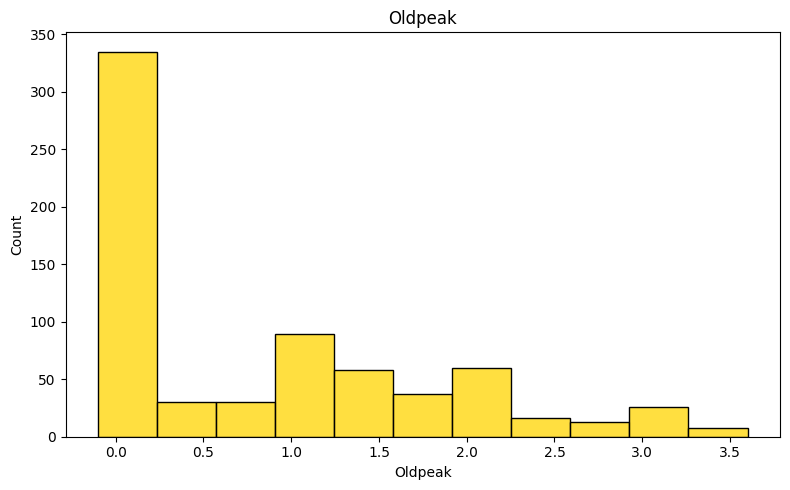

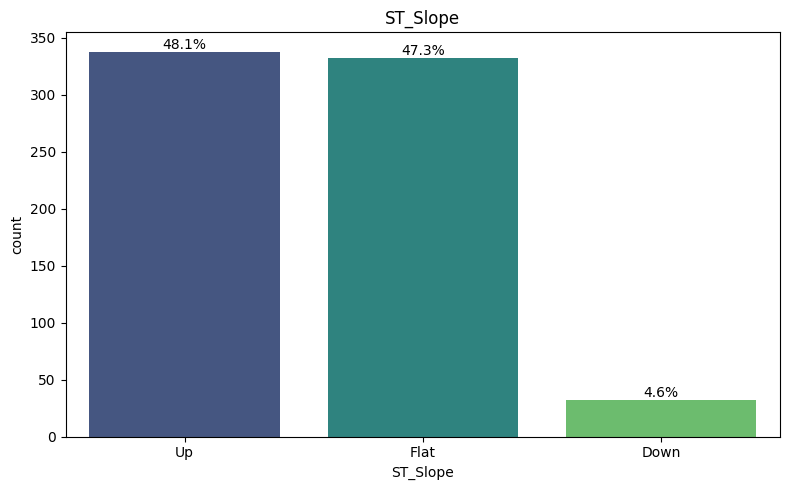

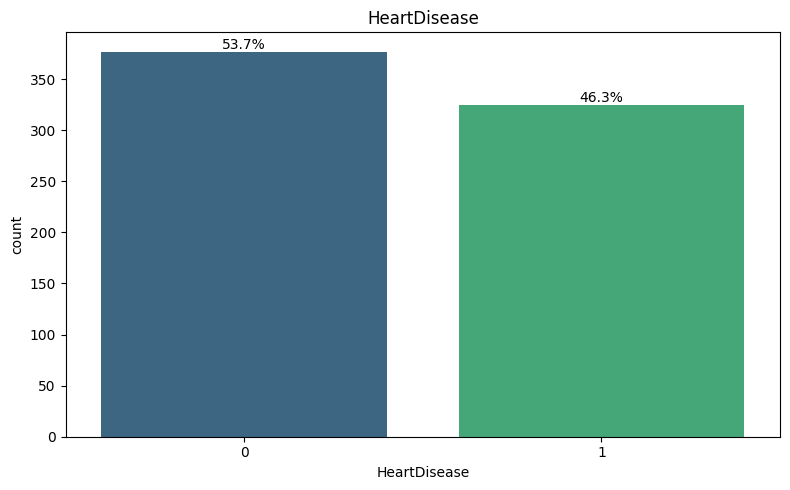

In [15]:
# List of categorical features
cat_features = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope', 'HeartDisease','FastingBS']

for feature in features:
    if feature in cat_features:
        plt.figure(figsize=(8, 5))
        ax = sns.countplot(
            data=df,
            x=feature,
            hue=feature,
            palette='viridis',
            legend=False
        )
        ax.set_title(feature)

        # Add percentage labels on the bars
        total = len(df[feature].dropna())
        for p in ax.patches:
            height = p.get_height()
            if height > 0:
                percentage = f'{100 * height / total:.1f}%'
                ax.annotate(
                    percentage,
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=10, color='black'
                )

        plt.tight_layout()
        plt.show()
    else:
        plt.figure(figsize=(8, 5))
        sns.histplot(df[feature], color=sns.color_palette('hsv')[0])
        plt.title(feature)
        plt.tight_layout()
        plt.show()

### 2 - Relationship between categorical explanatory variables and the target variable

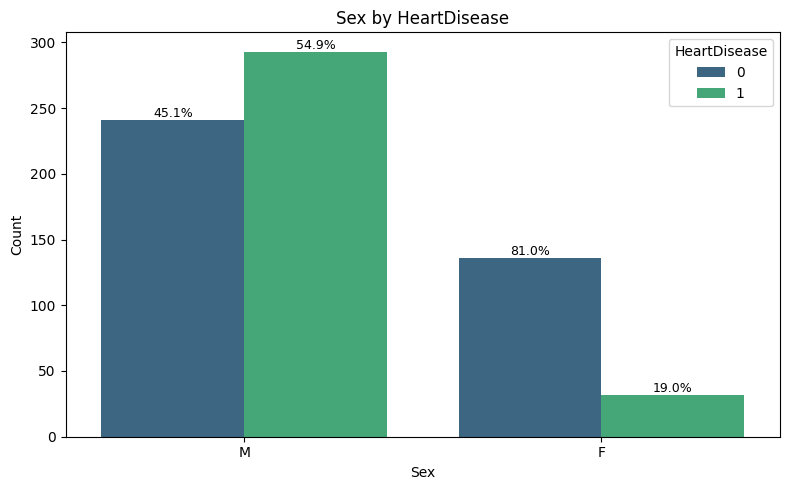

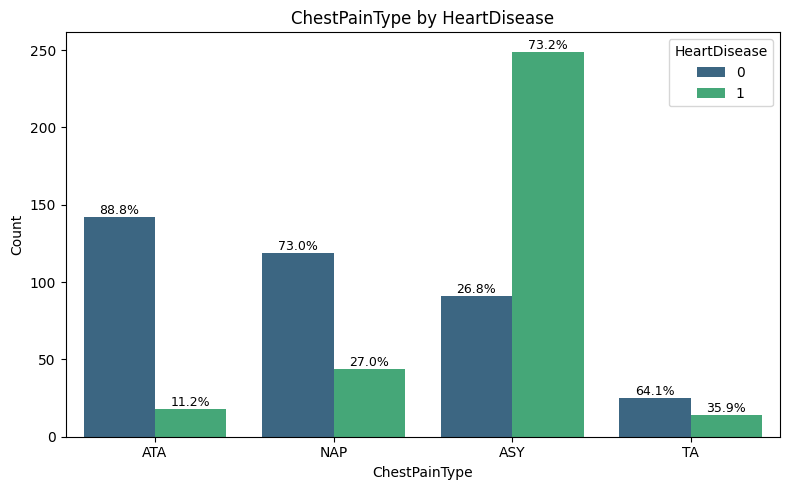

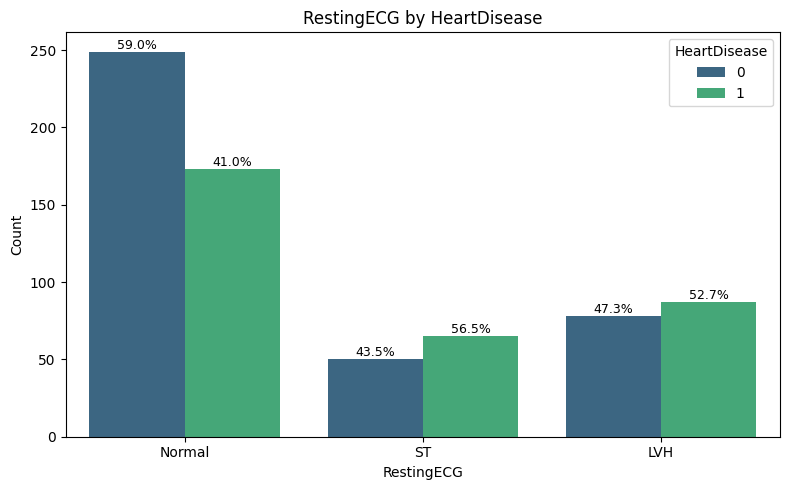

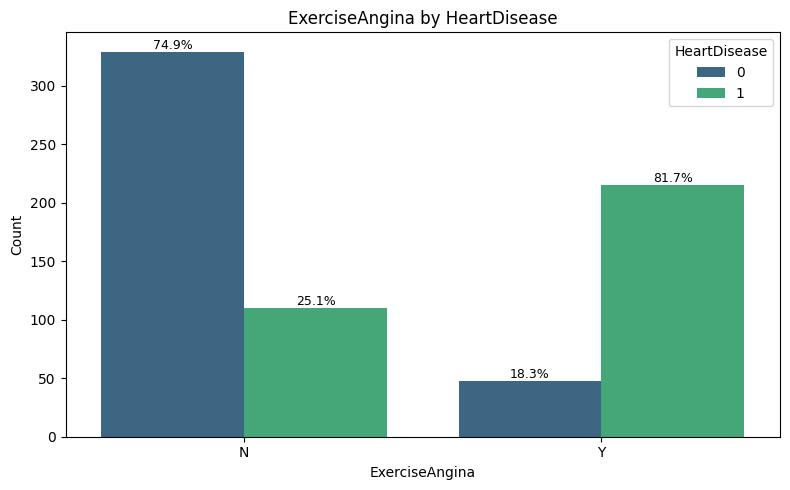

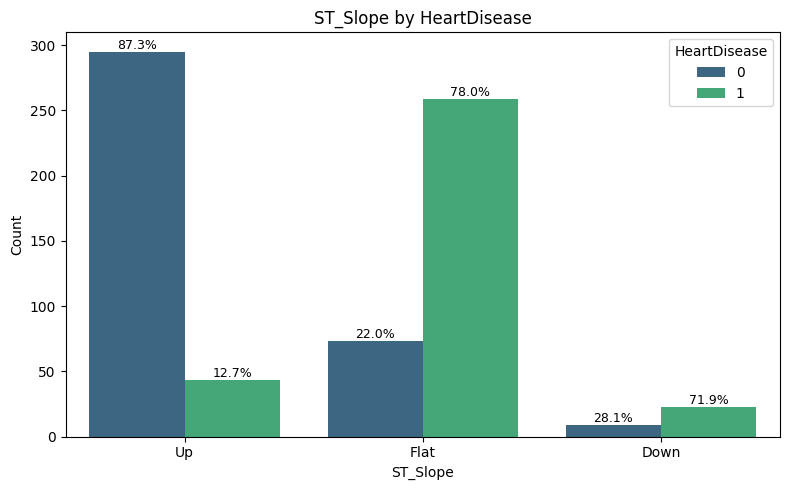

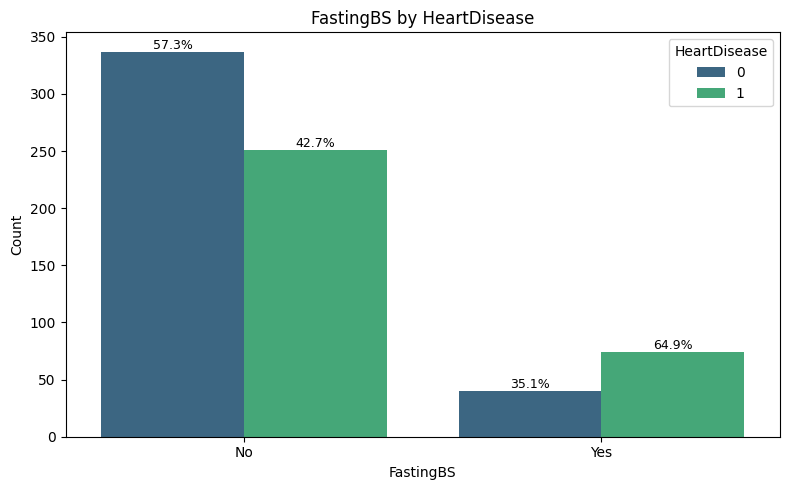

In [16]:
# Analysis of categorical variables
cat_cols = [col for col in cat_features if col != 'HeartDisease']

n_cols = 2
hue_order = df['HeartDisease'].dropna().unique().tolist()

for col in cat_cols:
    order = df[col].dropna().unique().tolist()
    counts = pd.crosstab(df[col], df['HeartDisease']).reindex(
        index=order, columns=hue_order, fill_value=0
    )
    totals = counts.sum(axis=1)

    fig, ax = plt.subplots(figsize=(8, 5))
    sns.countplot(
        data=df,
        x=col,
        order=order,
        hue='HeartDisease',
        hue_order=hue_order,
        palette='viridis',
        ax=ax
    )

    for container, disease in zip(ax.containers, hue_order):
        for i, bar in enumerate(container):
            count = counts.loc[order[i], disease]
            if count > 0:
                proportion = 100 * count / totals.loc[order[i]]
                ax.annotate(
                    f'{proportion:.1f}%',
                    (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha='center',
                    va='bottom',
                    fontsize=9
                )

    ax.set_title(f'{col} by HeartDisease')
    ax.set_xlabel(col)
    ax.set_ylabel('Count')
    ax.legend(title='HeartDisease')
    plt.tight_layout()
    plt.show()

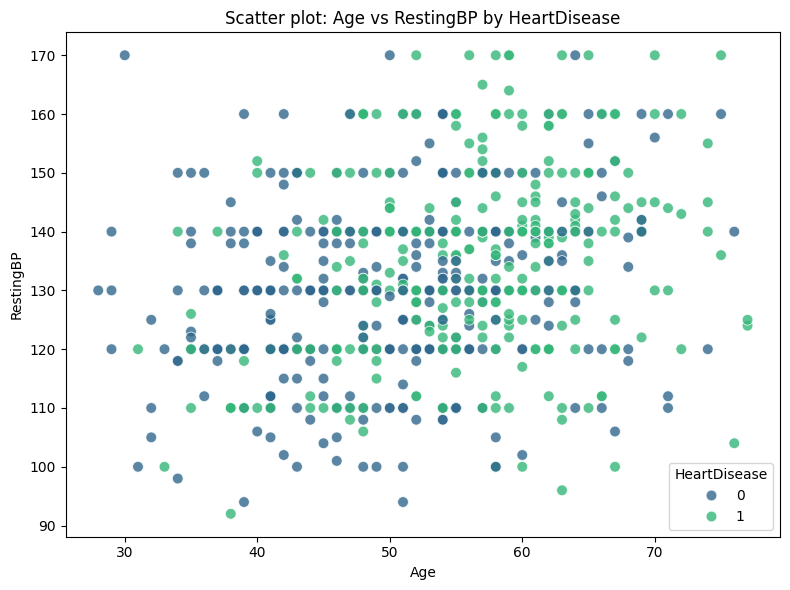

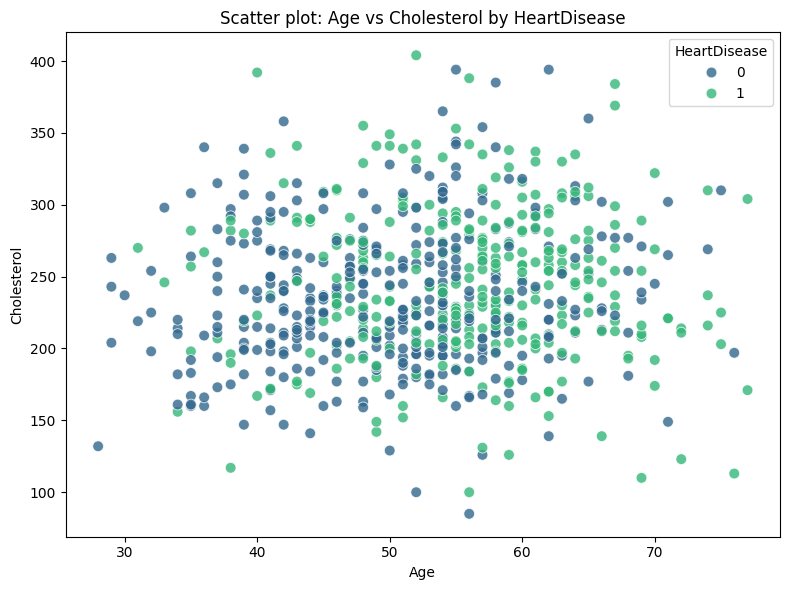

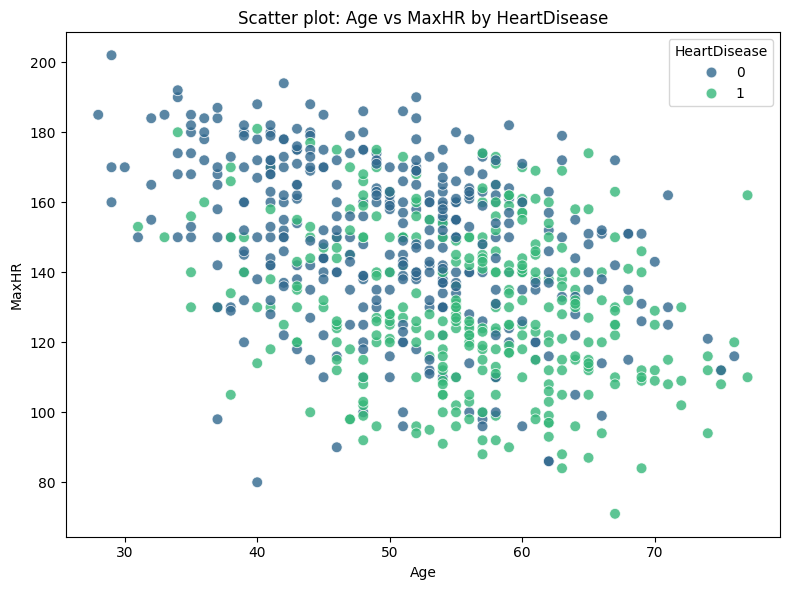

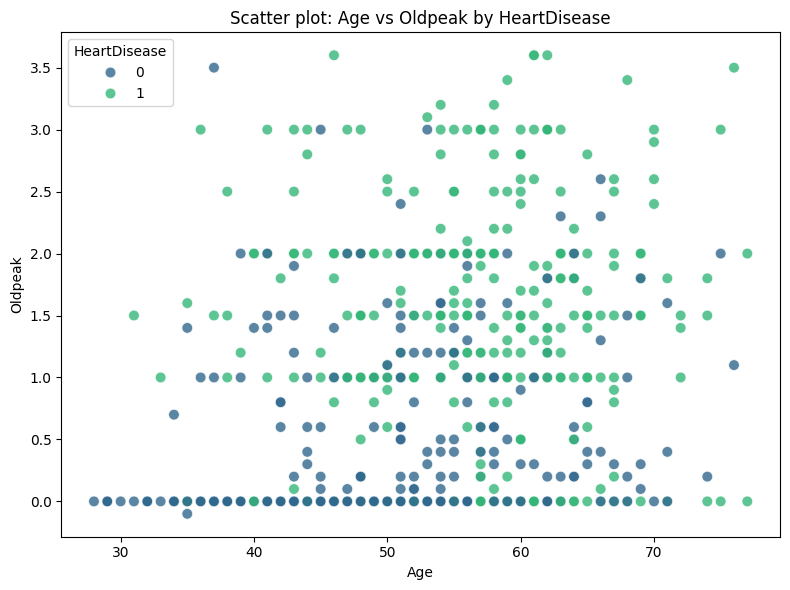

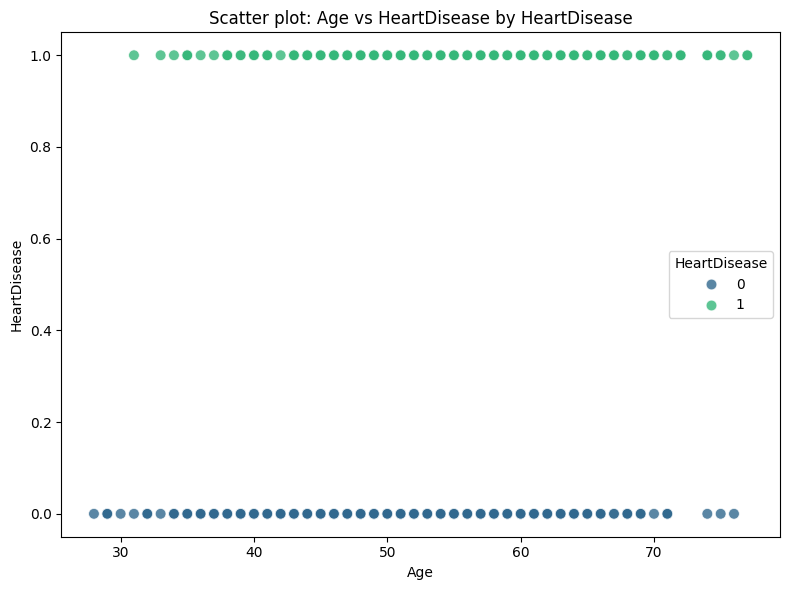

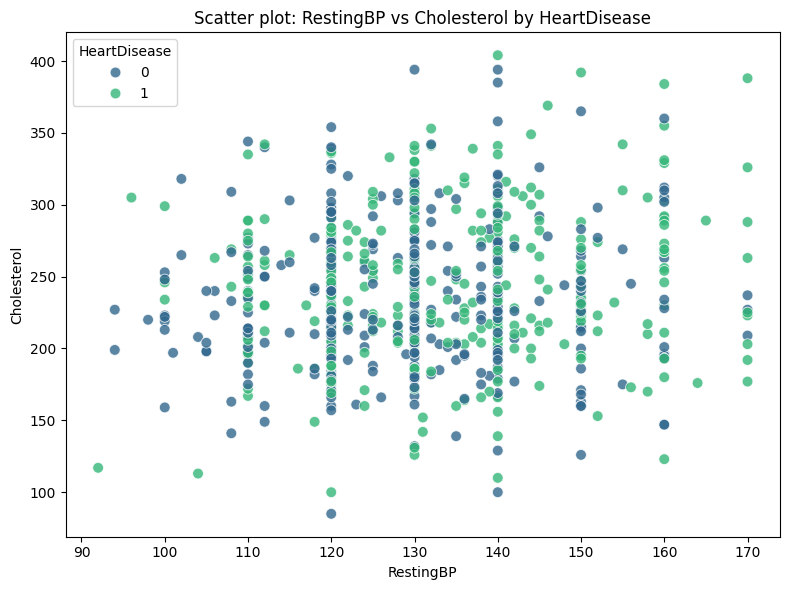

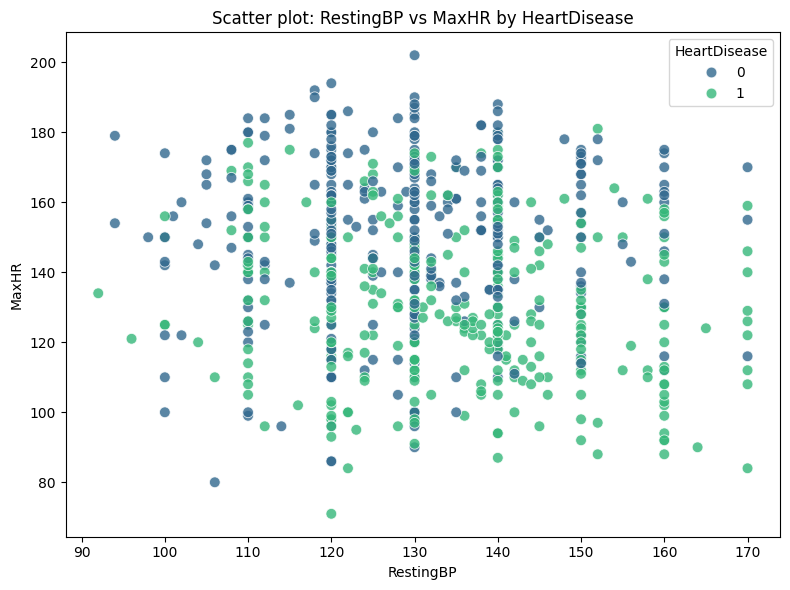

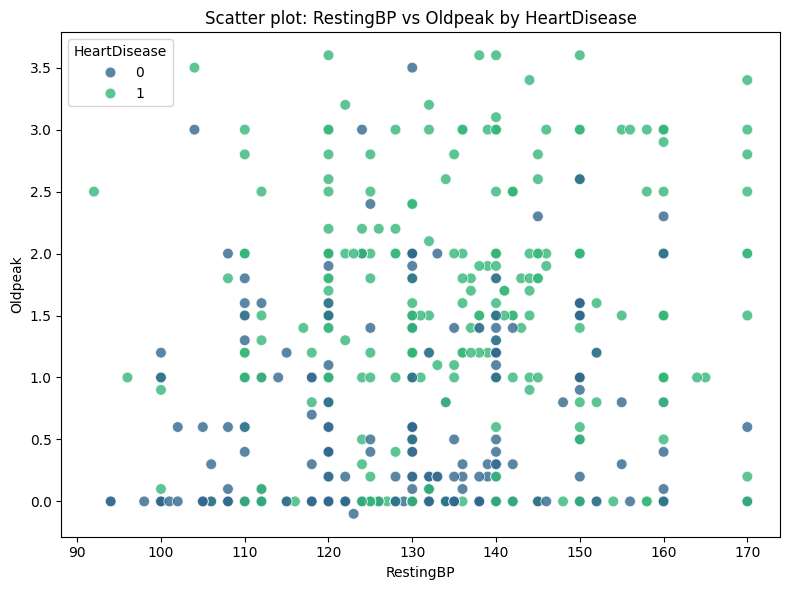

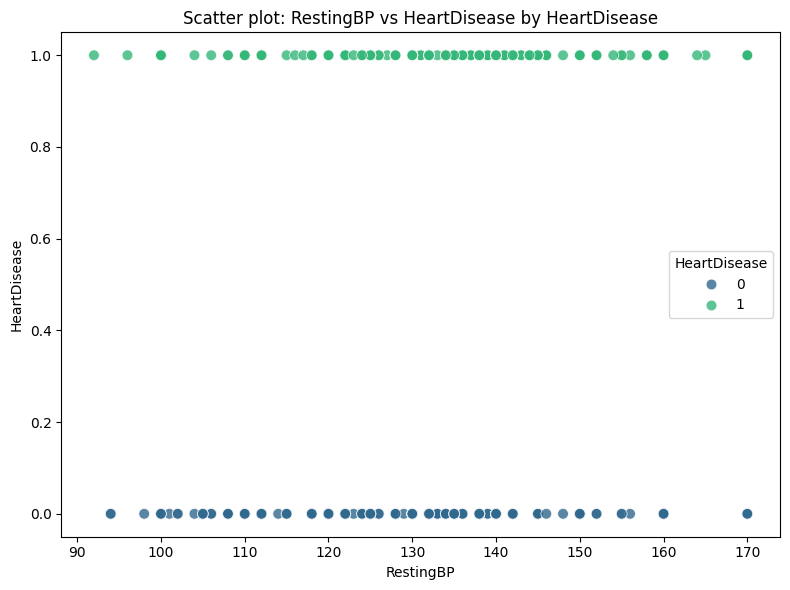

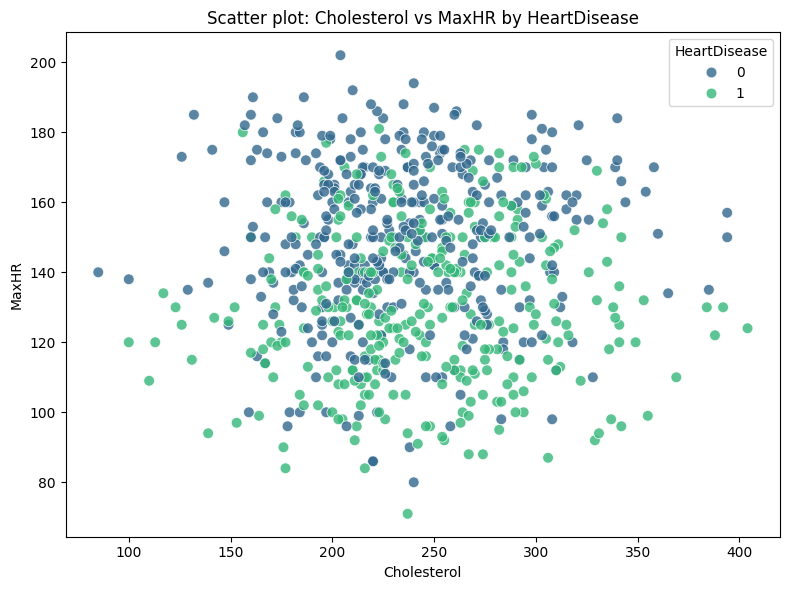

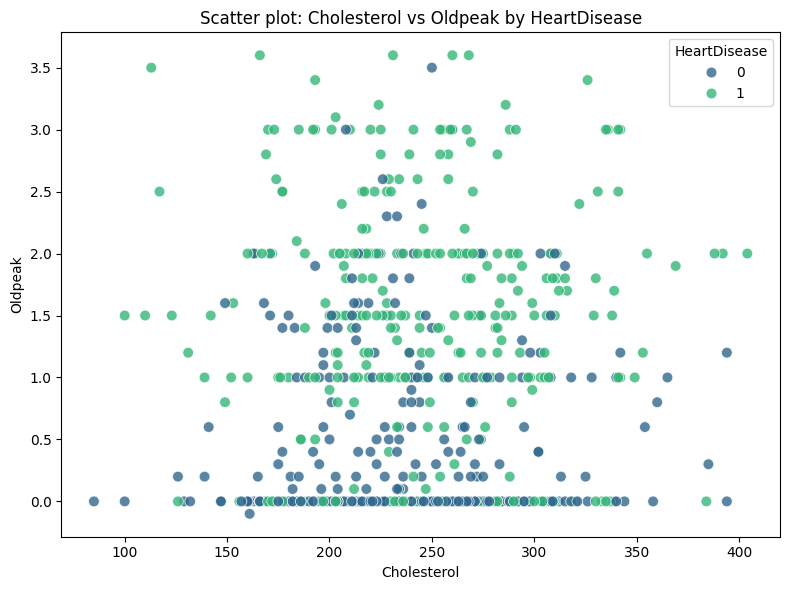

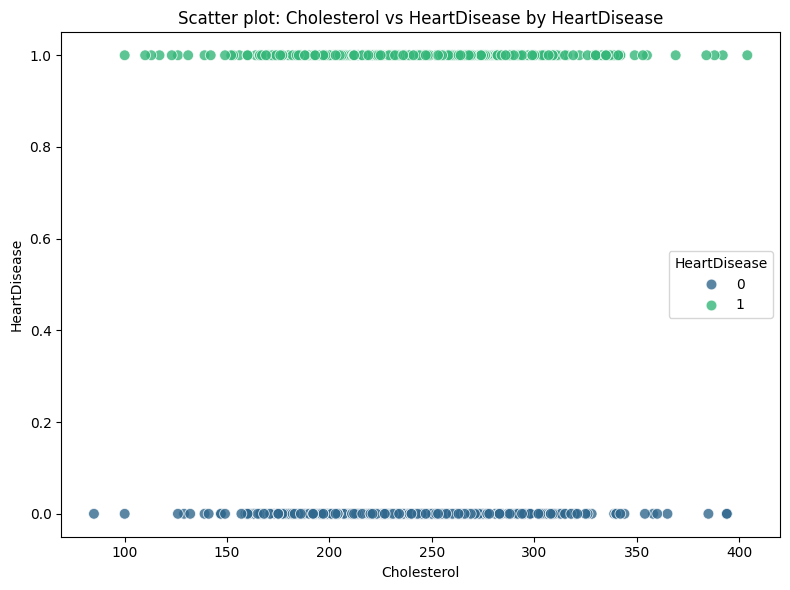

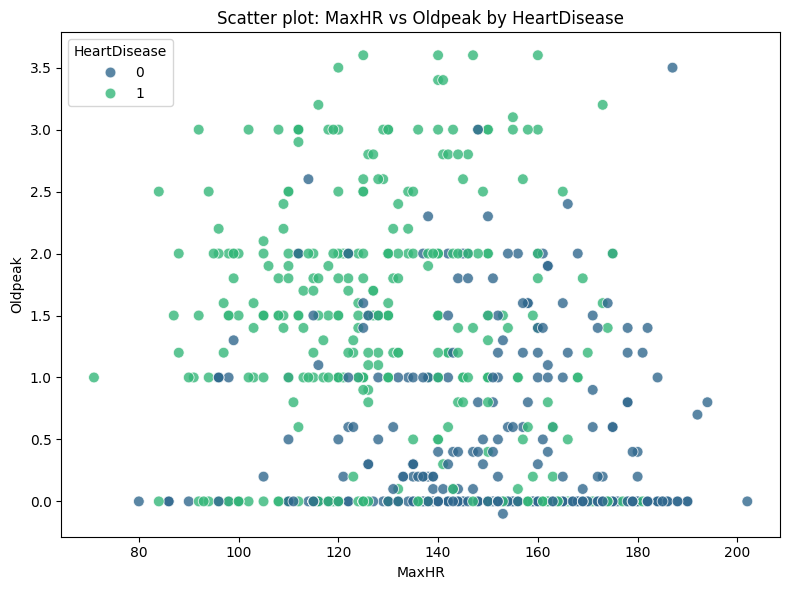

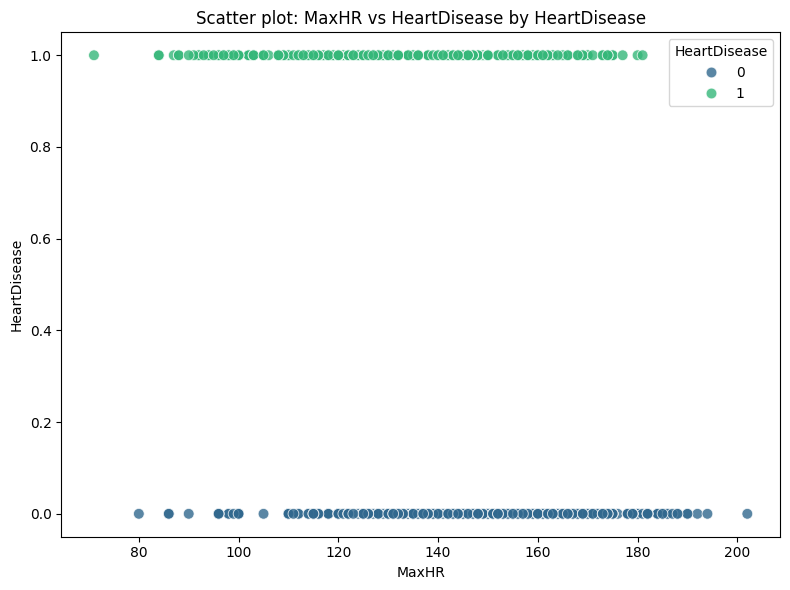

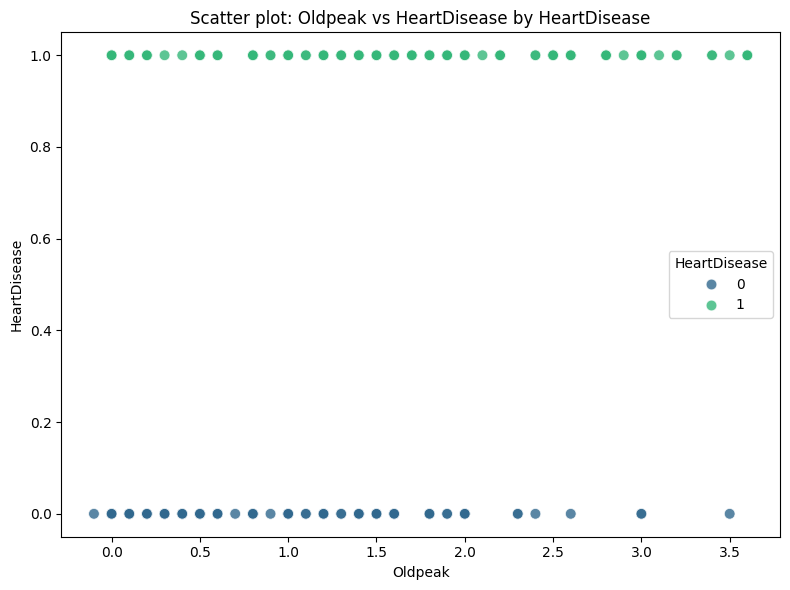

In [17]:
# Analysis of numerical variables
numeric_features = df.select_dtypes(include='number').columns.tolist()
for i in range(len(numeric_features)):
    for j in range(i + 1, len(numeric_features)):
        x_col = numeric_features[i]
        y_col = numeric_features[j]

        plt.figure(figsize=(8, 6))
        sns.scatterplot(
            data=df,
            x=x_col,
            y=y_col,
            hue='HeartDisease',
            palette='viridis',
            s=60,
            alpha=0.8
        )
        plt.title(f'Scatter plot: {x_col} vs {y_col} by HeartDisease')
        plt.legend(title='HeartDisease')
        plt.tight_layout()
        plt.show()

In [18]:
df.to_csv("cleaned_dataset.csv", index=False)

In [19]:
data = pd.read_csv("cleaned_dataset.csv")
data.head(3)

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,No,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,No,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,No,ST,98,N,0.0,Up,0


### Encoding variables

In [20]:
# Data preparation for modelling
X = data[['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol',
    'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina',
    'Oldpeak', 'ST_Slope']]
y = data['HeartDisease']
# Convert categorical variables into indicator variables (dummies)
X = pd.get_dummies(X, columns=['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope','FastingBS'], drop_first=True)

### Correlation heatmap and variable selection

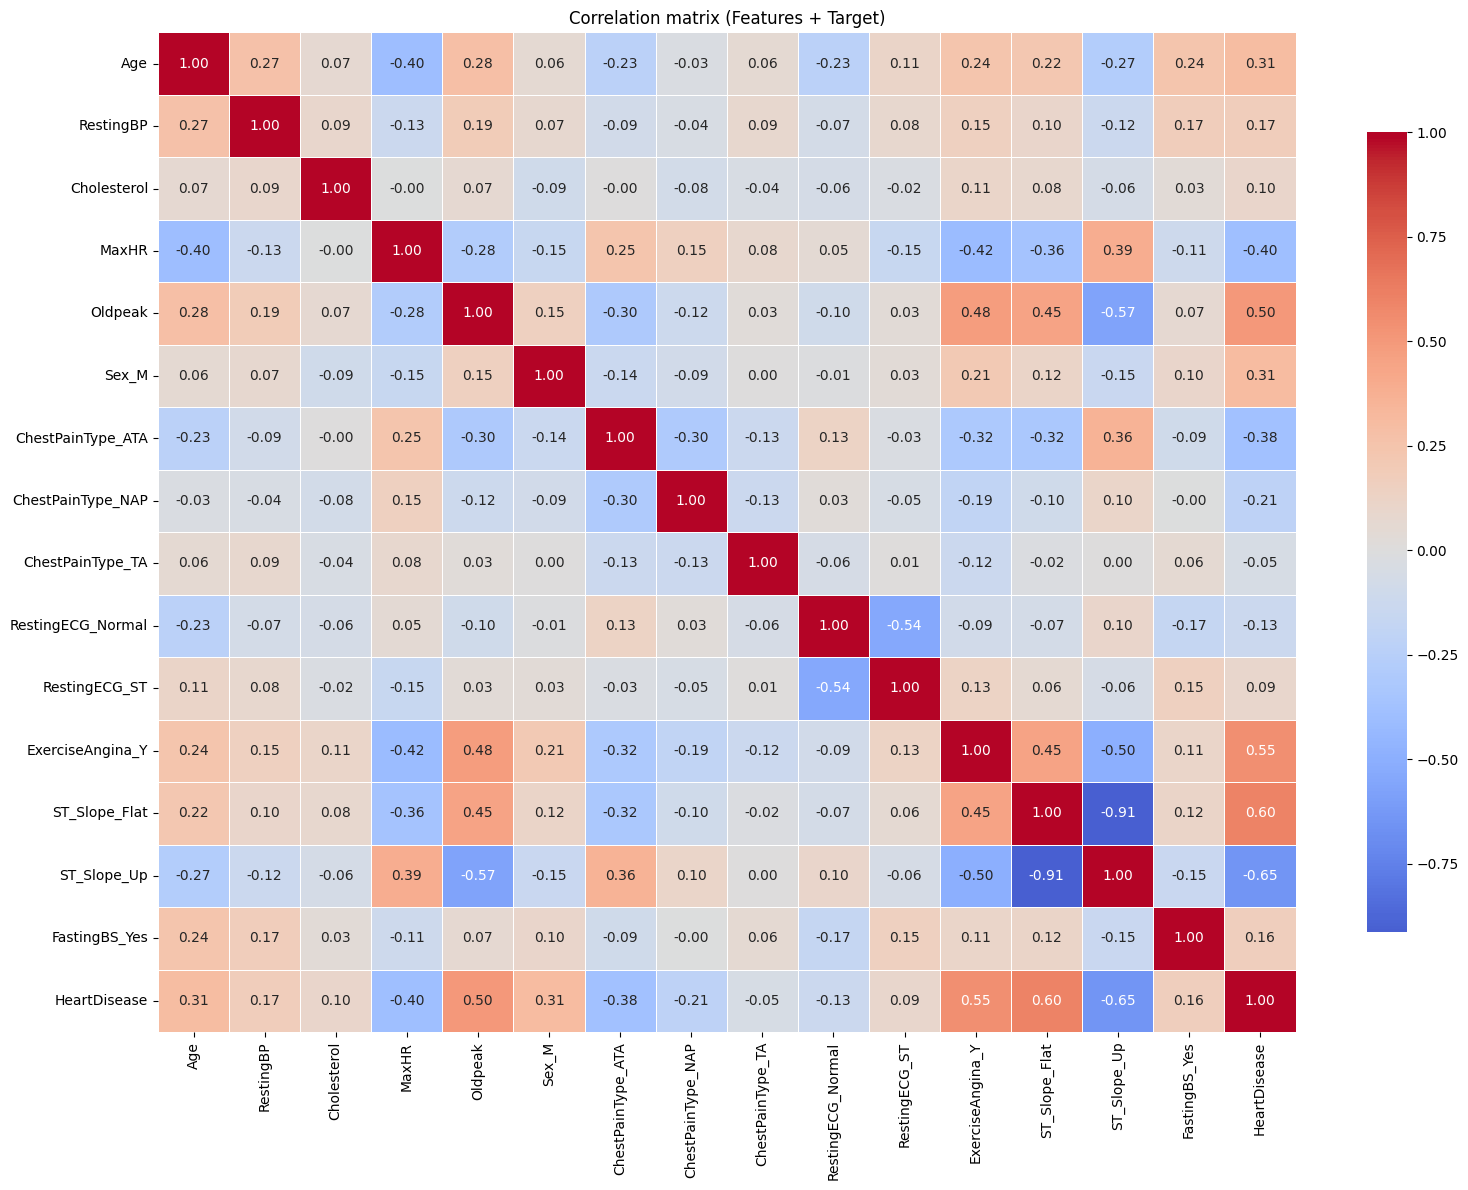

In [21]:
# 1. Combine X and y into a single DataFrame
X_corr = X.copy()
X_corr['HeartDisease'] = y

# 2. Encode the categorical variables (object) as 0/1
# (target included for the correlation)
colonnes_object = X_corr.select_dtypes(include=['object']).columns.tolist()
X_corr = pd.get_dummies(X_corr, columns=colonnes_object, dtype=int)

# 3. Make sure everything is float (for the correlation computation)
X_corr = X_corr.astype(float)

# 4. Create the correlation matrix
corr_matrix = X_corr.corr()

# 5. Display the heatmap
plt.figure(figsize=(16, 12))
sns.heatmap(
    corr_matrix, 
    cmap='coolwarm', 
    center=0, 
    annot=True,       # Set to True to show the values
    fmt='.2f',        # 2-decimal format
    linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)
plt.title('Correlation matrix (Features + Target)')
plt.tight_layout()
plt.show()

In [22]:
target_col = 'HeartDisease'

# Encoded levels corresponding to each categorical variable
variables_categorielles = [
    'Sex', 'ChestPainType', 'FastingBS',
    'RestingECG', 'ExerciseAngina', 'ST_Slope'
]

correlations = {}

for feature in X.columns:
    if feature in variables_categorielles:
        dummy_cols = [
            col for col in corr_matrix.columns
            if col.startswith(f'{feature}_')
        ]
        if dummy_cols:
            correlations[feature] = corr_matrix.loc[dummy_cols, target_col].abs().max()
    else:
        correlations[feature] = abs(corr_matrix.loc[feature, target_col])

classement = (
    pd.Series(correlations, name='Maximum absolute correlation')
    .sort_values(ascending=False)
    .rename_axis('Variable')
    .reset_index()
)

display(classement)

,Variable,Maximum absolute correlation
0,ST_Slope_Up,0.648845
1,ST_Slope_Flat,0.602515
2,ExerciseAngina_Y,0.550326
3,Oldpeak,0.502095
4,MaxHR,0.395452
5,ChestPainType_ATA,0.381880
6,Sex_M,0.306517
7,Age,0.305000
8,ChestPainType_NAP,0.212881
9,RestingBP,0.171118


In [23]:
# Variables whose maximum absolute correlation exceeds 0.5
variables_corr_sup_05 = classement[
    classement['Maximum absolute correlation'] > 0.5
].reset_index(drop=True).round(2)

display(variables_corr_sup_05)

,Variable,Maximum absolute correlation
0,ST_Slope_Up,0.65
1,ST_Slope_Flat,0.60
2,ExerciseAngina_Y,0.55
3,Oldpeak,0.50


In [24]:
# Variables whose maximum absolute correlation is below 0.5
variables_corr_inf_05 = classement[
    classement['Maximum absolute correlation'] < 0.5
].reset_index(drop=True).round(2)

display(variables_corr_inf_05)

,Variable,Maximum absolute correlation
0,MaxHR,0.40
1,ChestPainType_ATA,0.38
2,Sex_M,0.31
3,Age,0.31
4,ChestPainType_NAP,0.21
5,RestingBP,0.17
6,FastingBS_Yes,0.16
7,RestingECG_Normal,0.13
8,Cholesterol,0.10
9,RestingECG_ST,0.09


### Statistical tests to validate the choice of relevant variables

In [25]:
from scipy.stats import chi2_contingency
target = 'HeartDisease'

# Categorical variables with exactly 2 levels, excluding the target
categorical_features_2 = [
    col for col in df.select_dtypes(include=['object', 'category']).columns
    if col != target and df[col].nunique(dropna=True) == 2
]

results_chi2 = []

for feature in categorical_features_2:
    contingency_table = pd.crosstab(df[feature], df[target])

    chi2_stat, p_value, dof, _ = chi2_contingency(contingency_table)

    results_chi2.append({
        'Variable': feature,
        'Levels': df[feature].dropna().unique().tolist(),
        'Chi2': chi2_stat,
        'Degrees of freedom': dof,
        'p-value': p_value
    })

resultats_chi2 = (
    pd.DataFrame(results_chi2)
    .sort_values('p-value')
    .reset_index(drop=True)
)

display(resultats_chi2)

,Variable,Levels,Chi2,Degrees of freedom,p-value
0,ExerciseAngina,"[N, Y]",210.333030,1,1.162006e-47
1,Sex,"[M, F]",64.521773,1,9.547150e-16
2,FastingBS,"[No, Yes]",18.087440,1,2.109886e-05


In [26]:
from scipy.stats import chi2_contingency

target = 'HeartDisease'
categorical_features = [
	col for col in df.select_dtypes(include=['object', 'category']).columns
	if col != target and df[col].nunique(dropna=True) > 2
]

results = []

for feature in categorical_features:
	contingency_table = pd.crosstab(df[feature], df[target]).dropna()

	chi2, p_value, dof, _ = chi2_contingency(contingency_table)
	n = contingency_table.to_numpy().sum()
	rows, cols = contingency_table.shape

	tschuprow_t = np.sqrt(
		chi2 / (n * np.sqrt((rows - 1) * (cols - 1)))
	)

	results.append({
		'Variable': feature,
		'Number of levels': df[feature].nunique(dropna=True),
		"Tschuprow's T": tschuprow_t,
		'p-value': p_value
	})

resultats_tschuprow = (
	pd.DataFrame(results)
	.sort_values("Tschuprow's T", ascending=False)
	.reset_index(drop=True)
)

display(resultats_tschuprow)

,Variable,Number of levels,Tschuprow's T,p-value
0,ST_Slope,3,0.546019,5.345165e-65
1,ChestPainType,4,0.410012,4.713154e-44
2,RestingECG,3,0.111537,2.080234e-03


In [27]:
#
from tables.tests.test_suite import test
from sklearn.model_selection import train_test_split
test_size = 0.2
# seed = 8
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2  , random_state=42,stratify=y)

In [28]:
from sklearn.preprocessing import StandardScaler

colonnes_a_standardiser = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[colonnes_a_standardiser] = scaler.fit_transform(
    X_train[colonnes_a_standardiser]
)
X_test_scaled[colonnes_a_standardiser] = scaler.transform(
    X_test[colonnes_a_standardiser]
)

### Final dataset for Machine Learning

In [29]:
# Prepare the dataset for Machine Learning
train_ready = X_train_scaled.copy()
train_ready['HeartDisease'] = y_train
train_ready['Jeu'] = 'train'

test_ready = X_test_scaled.copy()
test_ready['HeartDisease'] = y_test
test_ready['Jeu'] = 'test'

jeu_ml = pd.concat([train_ready, test_ready]).sort_index()
jeu_ml.to_csv('Machine_Learning_ready_Dataset.csv', index=False)

print("File saved: Machine_Learning_ready_Dataset.csv")
display(jeu_ml.head())

File saved: Machine_Learning_ready_Dataset.csv


,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up,FastingBS_Yes,HeartDisease,Jeu
0,-1.305207,0.540931,0.958044,1.282929,-0.844417,True,True,False,False,True,False,False,False,True,False,0,train
1,-0.362028,1.827606,-1.184495,0.625572,0.199244,False,False,True,False,True,False,False,True,False,False,1,test
2,-1.619599,-0.102406,0.840106,-1.757344,-0.844417,True,True,False,False,False,True,False,False,True,False,0,test
3,-0.466826,0.412263,-0.516180,-1.346496,0.721075,False,False,False,False,True,False,True,True,False,False,1,train
4,0.161960,1.184268,-0.889650,-0.771310,-0.844417,True,False,True,False,True,False,False,False,True,False,0,train


In [31]:
import pandas as pd

# Load the dataset produced by the preprocessing notebook
data = pd.read_csv("Machine_Learning_ready_Dataset.csv")

# Split rows into train and test sets using the "Jeu" column, then drop that column
train = data[data["Jeu"] == "train"].drop(columns="Jeu")
test = data[data["Jeu"] == "test"].drop(columns="Jeu")

# Separate features (X) from the target (y) for each set
X_train, y_train = train.drop(columns="HeartDisease"), train["HeartDisease"]
X_test, y_test = test.drop(columns="HeartDisease"), test["HeartDisease"]